# Red Wine Quality Prediction using Machine Learning

**Assignment:** Machine Learning (10 Marks)  
**Task:** Predict the quality score of red wine from its physicochemical properties.

## 1. Introduction
This project uses the Red Wine Quality dataset. Each sample contains 11 physicochemical measurements and a sensory quality score. The target variable is `quality`.

## 2. Aim
To train and compare two regression models:
- Linear Regression
- Random Forest Regressor

The models are evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

**Note:** Run all cells from top to bottom. The notebook first looks for `winequality-red.csv` in the working folder. If it is not found, it downloads the original CSV from the UCI repository.


## 3. Import libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42


## 4. Load the dataset

In [2]:
# Load the CSV saved in the same folder; otherwise download it from UCI.
file_name = "winequality-red.csv"
uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

if os.path.exists(file_name):
    df = pd.read_csv(file_name, sep=";")
else:
    print("Local CSV not found. Downloading the original dataset from UCI...")
    df = pd.read_csv(uci_url, sep=";")
    df.to_csv(file_name, index=False)

print("Dataset shape:", df.shape)
display(df.head())


Local CSV not found. Downloading the original dataset from UCI...
Dataset shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 5. Understand and clean the data

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nMissing values in each column:")
display(df.isnull().sum())

print("\\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows, if any.
df = df.drop_duplicates().reset_index(drop=True)

# Convert all columns to numeric values and remove rows with missing values.
df = df.apply(pd.to_numeric, errors="coerce")
df = df.dropna().reset_index(drop=True)

print("\\nShape after cleaning:", df.shape)
display(df.describe().round(2))


Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quali

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


\nDuplicate rows: 240
\nShape after cleaning: (1359, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00,1359.00
mean,8.31,0.53,0.27,2.52,0.09,15.89,46.83,1.00,3.31,0.66,10.43,5.62
std,1.74,0.18,0.20,1.35,0.05,10.45,33.41,0.00,0.16,0.17,1.08,0.82
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.43,2.60,0.09,21.00,63.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


## 6. Exploratory data analysis

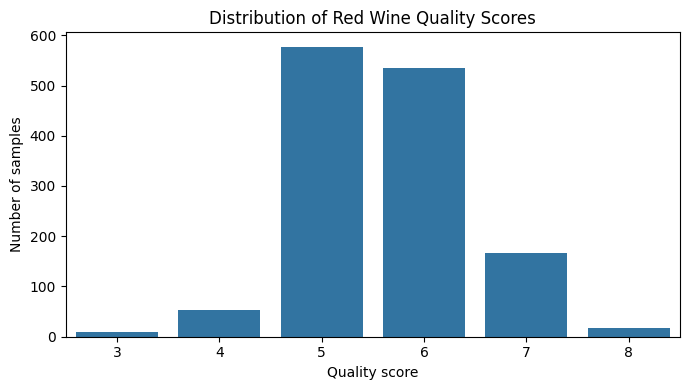

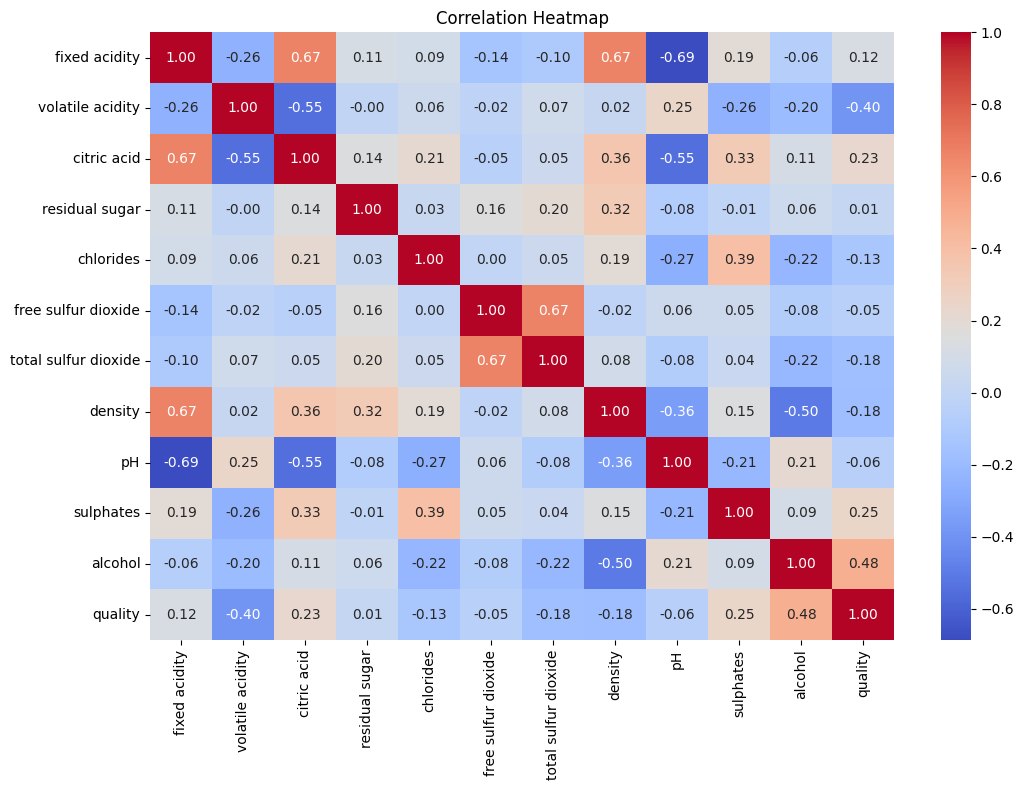

In [4]:
# Distribution of the target variable
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Red Wine Quality Scores")
plt.xlabel("Quality score")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## 7. Define input and target variables

The 11 physicochemical properties are the input features (`X`). The sensory quality score is the target (`y`).


In [5]:
X = df.drop(columns=["quality"])
y = df["quality"]

print("Number of input features:", X.shape[1])
print("Number of observations:", X.shape[0])


Number of input features: 11
Number of observations: 1359


## 8. Split the dataset

In [6]:
# 80% training data and 20% testing data.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1087
Testing samples: 272


## 9. Model 1 – Linear Regression

Linear Regression estimates the relationship between the input variables and the numerical quality score. Standardisation is included in a pipeline because the features have different scales.


In [7]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)


## 10. Model 2 – Random Forest Regressor

Random Forest is an ensemble learning method. It builds multiple decision trees and combines their predictions. It can model non-linear relationships between wine properties and quality.


In [8]:
random_forest_model = RandomForestRegressor(
    n_estimators=300,
    random_state=RANDOM_STATE,
    min_samples_split=2,
    min_samples_leaf=1,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)
rf_predictions = random_forest_model.predict(X_test)


## 11. Evaluate and compare both models

In [9]:
def evaluate_model(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"Model": model_name, "MAE": mae, "RMSE": rmse, "R2 Score": r2}

results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Random Forest Regressor", y_test, rf_predictions)
])

display(results.round(4))

best_model_name = results.sort_values("RMSE").iloc[0]["Model"]
print("Model with the lower RMSE on this test split:", best_model_name)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.5041,0.6565,0.3915
1,Random Forest Regressor,0.4668,0.6189,0.4593


Model with the lower RMSE on this test split: Random Forest Regressor


## 12. Visualise actual vs predicted values

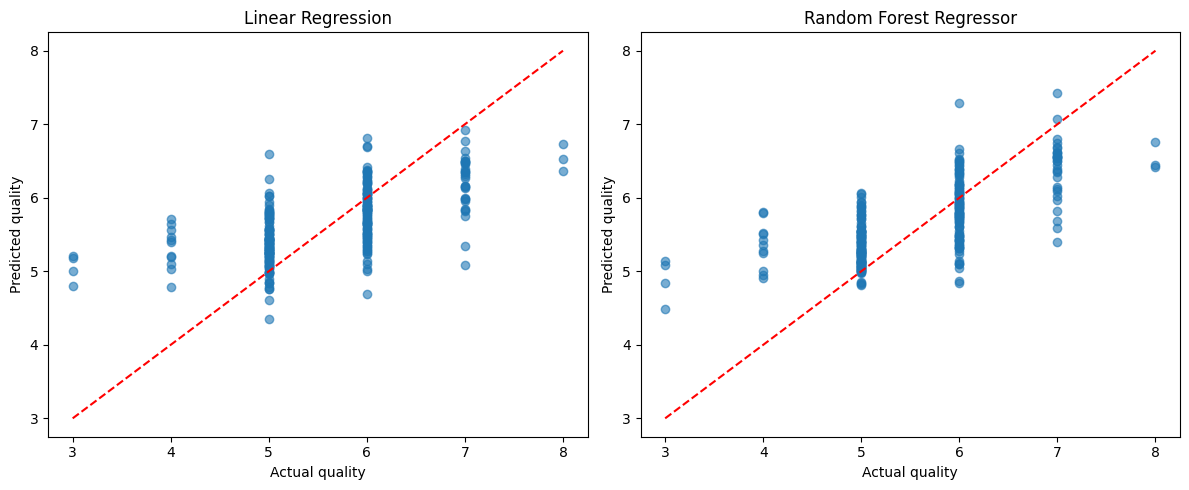

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, linear_predictions, alpha=0.6)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_title("Linear Regression")
axes[0].set_xlabel("Actual quality")
axes[0].set_ylabel("Predicted quality")

axes[1].scatter(y_test, rf_predictions, alpha=0.6)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[1].set_title("Random Forest Regressor")
axes[1].set_xlabel("Actual quality")
axes[1].set_ylabel("Predicted quality")

plt.tight_layout()
plt.show()


## 13. Feature importance (Random Forest)

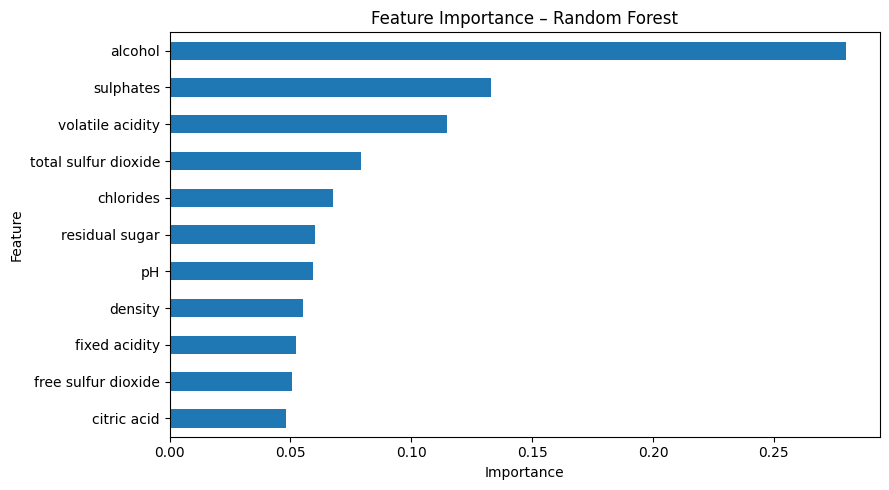

,Importance
alcohol,0.2799
sulphates,0.1328
volatile acidity,0.1148
total sulfur dioxide,0.0790
chlorides,0.0675
residual sugar,0.0600
pH,0.0592
density,0.0553
fixed acidity,0.0523
free sulfur dioxide,0.0508


In [11]:
importance = pd.Series(
    random_forest_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Feature Importance – Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance.to_frame("Importance").round(4))


## 14. Conclusion

In this project, two regression models were trained to predict red wine quality using physicochemical properties. Their performance was compared using MAE, RMSE and R² score.

- MAE represents the average absolute difference between actual and predicted quality scores.
- RMSE penalises larger prediction errors more strongly.
- R² indicates how much variation in the target is explained by the model.

Use the evaluation table generated above to identify which model performed better on this test split. The feature-importance chart shows which input variables the Random Forest model relied on most. These are predictive associations in this dataset and do not prove causation.

## 15. Dataset reference

Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). *Wine Quality*. UCI Machine Learning Repository. https://doi.org/10.24432/C56S3T

Kaggle dataset page: https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009\n\nOriginal dataset repository / direct CSV fallback: https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv
